In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_game = pd.read_csv("steam_games.csv")
df_game.head(2)

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,DLC count,About the game,Supported languages,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,20200,Galactic Bowling,"Oct 21, 2008",0 - 20000,0,0,19.99,0,Galactic Bowling is an exaggerated and stylize...,['English'],...,0,0,0,Perpetual FX Creative,Perpetual FX Creative,"Single-player,Multi-player,Steam Achievements,...","Casual,Indie,Sports","Indie,Casual,Sports,Bowling",https://cdn.akamai.steamstatic.com/steam/apps/...,http://cdn.akamai.steamstatic.com/steam/apps/2...
1,655370,Train Bandit,"Oct 12, 2017",0 - 20000,0,0,0.99,0,THE LAW!! Looks to be a showdown atop a train....,"['English', 'French', 'Italian', 'German', 'Sp...",...,0,0,0,Rusty Moyher,Wild Rooster,"Single-player,Steam Achievements,Full controll...","Action,Indie","Indie,Action,Pixel Graphics,2D,Retro,Arcade,Sc...",https://cdn.akamai.steamstatic.com/steam/apps/...,http://cdn.akamai.steamstatic.com/steam/apps/2...


In [3]:
#1. Quais são os dez jogos mais bem avaliados, de acordo com o Metacritic? No caso de notas repetidas, 
# ordenar os jogos de acordo com suas datas de lançamento (do mais velho para o mais recente).


# Converter 'Release date' para datetime e 'Metacritic score' para numérico
df_game['Release date'] = pd.to_datetime(df_game['Release date'], errors='coerce')
df_game['Metacritic score'] = pd.to_numeric(df_game['Metacritic score'], errors='coerce')

# Remover valores nulos em 'Metacritic score'
df_game = df_game.dropna(subset=['Metacritic score'])

# Remover duplicatas baseando-se no nome do jogo
df_game = df_game.drop_duplicates(subset=['Name'])

# Ordenar por Metacritic score (descendente) e Release date (ascendente)
df_sorted = df_game.sort_values(by=['Metacritic score', 'Release date'], ascending=[False, True])

# Selecionar os 10 melhores jogos
top_10 = df_sorted.head(10)

# Exibir os resultados
print(top_10[['Name', 'Metacritic score', 'Release date']].to_string(index=False))

                                                           Name  Metacritic score Release date
                                  Disco Elysium - The Final Cut                97   2019-10-15
                                                Persona 5 Royal                97   2022-10-20
                                                      Half-Life                96   1998-11-08
                                                    Half-Life 2                96   2004-11-16
                                                      BioShock™                96   2007-08-21
                                             Grand Theft Auto V                96   2015-04-13
                                                       Portal 2                95   2011-04-18
                                   Sid Meier's Civilization® IV                94   2006-10-25
                                                          QUAKE                94   2007-08-03
The Elder Scrolls IV: Oblivion® Game of the Year E

In [4]:
# Definindo palavras-chave para identificar jogos de RPG
rpg_keywords = ['role-playing', 'rpg', 'role play', 'jogo de interpretação', 'RPG']

# Filtrando os jogos de role-playing
df_rpg = df_game[df_game['About the game'].str.contains('|'.join(rpg_keywords), case=False, na=False)]

# Convertendo as colunas necessárias para tipos numéricos
df_rpg['DLC count'] = pd.to_numeric(df_rpg['DLC count'], errors='coerce')
df_rpg['Metacritic score'] = pd.to_numeric(df_rpg['Metacritic score'], errors='coerce')
df_rpg['Screenshots'] = df_rpg['Screenshots'].apply(lambda x: len(x.split(',')) if isinstance(x, str) else 0)
df_rpg['Movies'] = df_rpg['Movies'].apply(lambda x: len(x.split(',')) if isinstance(x, str) else 0)

# Calculando o número total de materiais de demonstração (capturas de tela + filmes)
df_rpg['Materials'] = df_rpg['Screenshots'] + df_rpg['Movies']

# Usando as colunas 'Positive' e 'Negative' diretamente
# Calculando as estatísticas médias e máximas
mean_dlc = df_rpg['DLC count'].mean()
max_dlc = df_rpg['DLC count'].max()
mean_positive = df_rpg['Positive'].mean() * 100  # Porcentagem de jogos com avaliação positiva
max_positive = df_rpg['Positive'].sum()  # Total de jogos positivos
mean_negative = df_rpg['Negative'].mean() * 100  # Porcentagem de jogos com avaliação negativa
max_negative = df_rpg['Negative'].sum()  # Total de jogos negativos
mean_materials = df_rpg['Materials'].mean()
max_materials = df_rpg['Materials'].max()

# Exibindo os resultados
print(f"Média de DLCs: {mean_dlc:.2f}")
print(f"Máximo de DLCs: {max_dlc}")
print(f"Média de avaliações positivas (percentual): {mean_positive:.2f}%")
print(f"Máximo de avaliações positivas (total): {max_positive}")
print(f"Média de avaliações negativas (percentual): {mean_negative:.2f}%")
print(f"Máximo de avaliações negativas (total): {max_negative}")
print(f"Média de materiais de demonstração (capturas de tela + filmes): {mean_materials:.2f}")
print(f"Máximo de materiais de demonstração: {max_materials}")


Média de DLCs: 1.59
Máximo de DLCs: 2366
Média de avaliações positivas (percentual): 142646.77%
Máximo de avaliações positivas (total): 8262101
Média de avaliações negativas (percentual): 22574.76%
Máximo de avaliações negativas (total): 1307530
Média de materiais de demonstração (capturas de tela + filmes): 11.73
Máximo de materiais de demonstração: 158


C:\Users\paulo\AppData\Local\Temp\ipykernel_23180\2146675094.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_rpg['DLC count'] = pd.to_numeric(df_rpg['DLC count'], errors='coerce')
C:\Users\paulo\AppData\Local\Temp\ipykernel_23180\2146675094.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_rpg['Metacritic score'] = pd.to_numeric(df_rpg['Metacritic score'], errors='coerce')
C:\Users\paulo\AppData\Local\Temp\ipykernel_23180\2146675094.py:10: SettingWithCopyWarning: 
A value is trying to be set on 

In [5]:
# Filtrando os jogos pagos (Price > 0)
df_paid_games = df_game[df_game['Price'] > 0]

# Contando o número de jogos pagos por empresa (Publisher)
publisher_game_count = df_paid_games['Publishers'].value_counts()

# Pegando as 5 empresas que mais publicam jogos pagos
top_5_publishers = publisher_game_count.head(5).index

# Filtrando os jogos pagos dessas 5 empresas
df_top_5_publishers = df_paid_games[df_paid_games['Publishers'].isin(top_5_publishers)]

# Convertendo as colunas necessárias para numéricos
df_top_5_publishers['Metacritic score'] = pd.to_numeric(df_top_5_publishers['Metacritic score'], errors='coerce')
df_top_5_publishers['Positive'] = pd.to_numeric(df_top_5_publishers['Positive'], errors='coerce')

# Calculando a média e mediana de avaliações positivas para as 5 empresas
avg_positive = df_top_5_publishers.groupby('Publishers')['Positive'].mean()
median_positive = df_top_5_publishers.groupby('Publishers')['Positive'].median()

# Exibindo as empresas e as estatísticas de avaliações positivas
for publisher in top_5_publishers:
    print(f"\nPublisher: {publisher}")
    print(f"Média de avaliações positivas: {avg_positive[publisher]:.2f}")
    print(f"Mediana de avaliações positivas: {median_positive[publisher]:.2f}")



Publisher: Big Fish Games
Média de avaliações positivas: 7.36
Mediana de avaliações positivas: 5.00

Publisher: 8floor
Média de avaliações positivas: 4.47
Mediana de avaliações positivas: 3.00

Publisher: Strategy First
Média de avaliações positivas: 279.91
Mediana de avaliações positivas: 23.50

Publisher: Laush Studio
Média de avaliações positivas: 19.78
Mediana de avaliações positivas: 12.00

Publisher: HH-Games
Média de avaliações positivas: 10.54
Mediana de avaliações positivas: 9.00


C:\Users\paulo\AppData\Local\Temp\ipykernel_23180\3347389911.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_top_5_publishers['Metacritic score'] = pd.to_numeric(df_top_5_publishers['Metacritic score'], errors='coerce')
C:\Users\paulo\AppData\Local\Temp\ipykernel_23180\3347389911.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_top_5_publishers['Positive'] = pd.to_numeric(df_top_5_publishers['Positive'], errors='coerce')


In [6]:
# Convertendo a coluna 'Release date' para o tipo datetime
df_game['Release date'] = pd.to_datetime(df_game['Release date'], errors='coerce')

# Filtrando os jogos que suportam Linux e foram lançados entre 2018 e 2022
df_linux_games = df_game[(df_game['Linux'] == True) & (df_game['Release date'].dt.year >= 2018) & (df_game['Release date'].dt.year <= 2022)]

# Contando o número de jogos por ano
games_by_year = df_linux_games['Release date'].dt.year.value_counts().sort_index()

# Exibindo o número de jogos lançados por ano entre 2018 e 2022
print(games_by_year)

# Verificando se houve crescimento entre 2018 e 2022
growth = games_by_year.loc[2022] > games_by_year.loc[2018] if 2022 in games_by_year and 2018 in games_by_year else None

# Resultado sobre o crescimento
if growth is not None:
    if growth:
        print("O número de jogos compatíveis com Linux cresceu entre 2018 e 2022.")
    else:
        print("O número de jogos compatíveis com Linux não cresceu entre 2018 e 2022.")
else:
    print("Não foi possível determinar o crescimento entre 2018 e 2022, pois os dados para esses anos estão ausentes.")


Release date
2018    1162
2019     918
2020    1079
2021    1206
2022    1297
Name: count, dtype: int64
O número de jogos compatíveis com Linux cresceu entre 2018 e 2022.


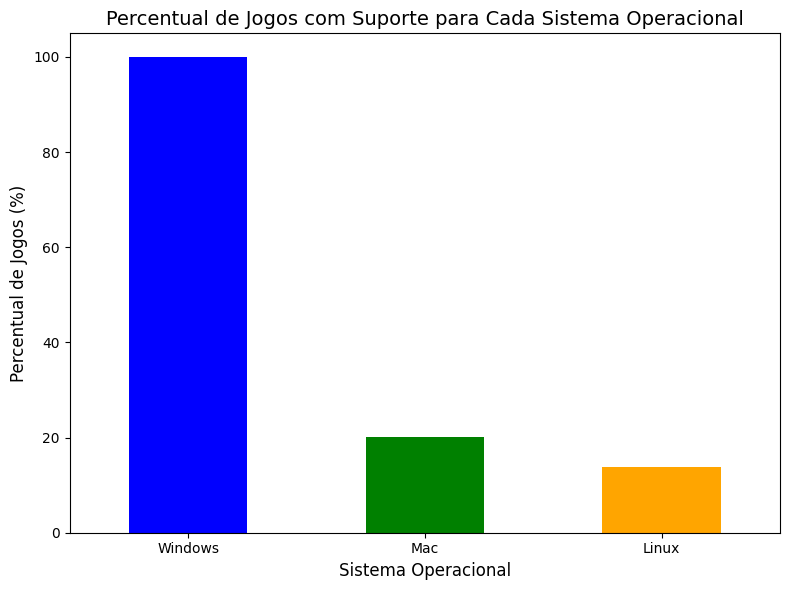

In [7]:
# Contando os votos para cada sistema operacional
os_columns = ['Windows', 'Mac', 'Linux']  # Colunas que indicam suporte para sistemas operacionais
os_support_count = df_game[os_columns].sum()  # Conta quantos jogos suportam cada sistema operacional

# Calculando o percentual de jogos que suportam cada sistema operacional
total_games = len(df_game)
os_support_percentage = (os_support_count / total_games) * 100

# Criando o gráfico
plt.figure(figsize=(8, 6))
os_support_percentage.plot(kind='bar', color=['blue', 'green', 'orange'])

# Adicionando título e rótulos
plt.title('Percentual de Jogos com Suporte para Cada Sistema Operacional', fontsize=14)
plt.xlabel('Sistema Operacional', fontsize=12)
plt.ylabel('Percentual de Jogos (%)', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()

# Exibindo o gráfico
plt.show()


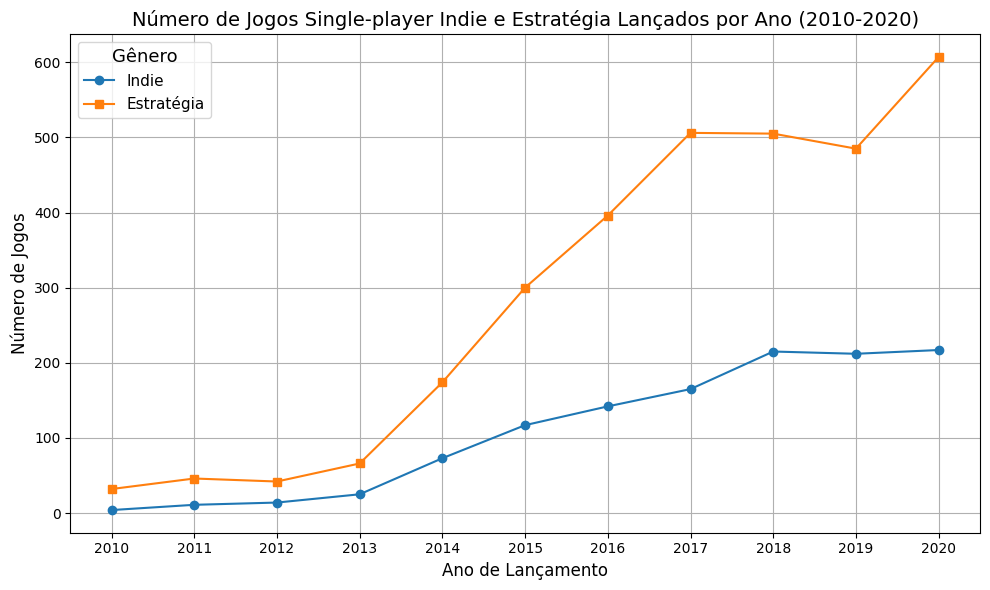

In [8]:
# Filtrando apenas jogos Single-player
df_single_player = df_game[df_game['Categories'].str.contains('Single-player', case=False, na=False)]

# Filtrando os jogos dos gêneros Indie e Estratégia (ambos na coluna About the game)
df_indie = df_single_player[df_single_player['About the game'].str.contains('Indie', case=False, na=False)]
df_strategy = df_single_player[df_single_player['About the game'].str.contains('Strategy', case=False, na=False)]

# Filtrando os jogos lançados entre 2010 e 2020
df_indie = df_indie[(df_indie['Release date'].dt.year >= 2010) & (df_indie['Release date'].dt.year <= 2020)]
df_strategy = df_strategy[(df_strategy['Release date'].dt.year >= 2010) & (df_strategy['Release date'].dt.year <= 2020)]

# Contando o número de jogos por ano para cada gênero
indie_by_year = df_indie.groupby(df_indie['Release date'].dt.year).size()
strategy_by_year = df_strategy.groupby(df_strategy['Release date'].dt.year).size()

# Criando o gráfico
plt.figure(figsize=(10, 6))
plt.plot(indie_by_year.index, indie_by_year.values, marker='o', linestyle='-', label='Indie')
plt.plot(strategy_by_year.index, strategy_by_year.values, marker='s', linestyle='-', label='Estratégia')

# Adicionando título e rótulos
plt.title('Número de Jogos Single-player Indie e Estratégia Lançados por Ano (2010-2020)', fontsize=14)
plt.xlabel('Ano de Lançamento', fontsize=12)
plt.ylabel('Número de Jogos', fontsize=12)
plt.xticks(range(2010, 2021))
plt.legend(title='Gênero', title_fontsize='13', fontsize='11')
plt.grid(True)

# Exibindo o gráfico
plt.tight_layout()
plt.show()

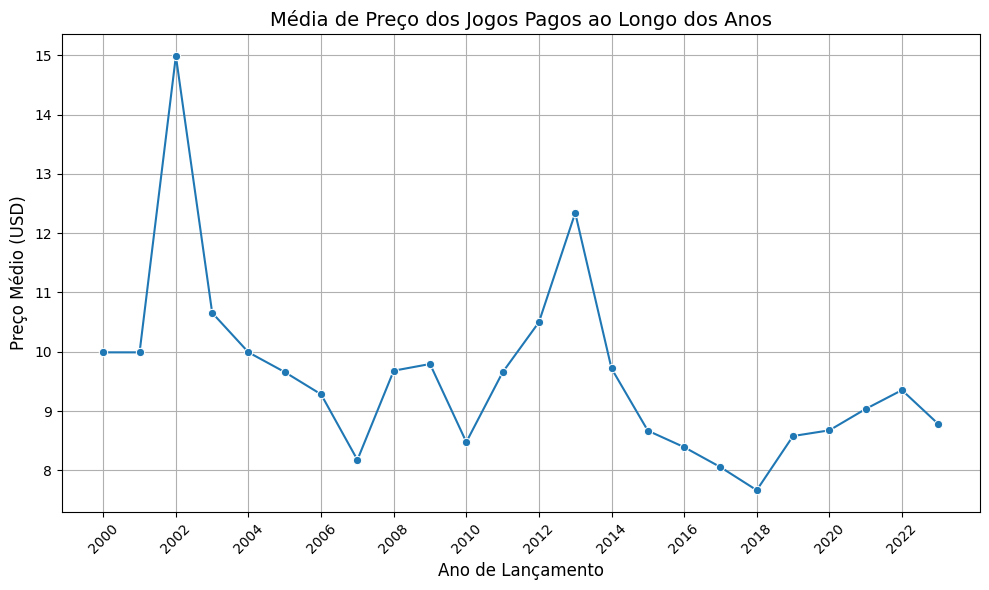

In [15]:
df_game['Price'] = pd.to_numeric(df_game['Price'], errors='coerce')

# Convertendo a coluna de data para datetime
df_game['Release date'] = pd.to_datetime(df_game['Release date'], errors='coerce')

# Filtrando jogos pagos (preço maior que 0) e lançados a partir do ano 2000
df_paid = df_game[(df_game['Price'] > 0) & (df_game['Release date'].dt.year >= 2000)]

# Calculando a média de preço por ano
avg_price_by_year = df_paid.groupby(df_paid['Release date'].dt.year)['Price'].mean()

# Criando o gráfico
plt.figure(figsize=(10, 6))
sns.lineplot(x=avg_price_by_year.index, y=avg_price_by_year.values, marker='o')

# Adicionando título e rótulos
plt.title('Média de Preço dos Jogos Pagos ao Longo dos Anos', fontsize=14)
plt.xlabel('Ano de Lançamento', fontsize=12)
plt.ylabel('Preço Médio (USD)', fontsize=12)
plt.xticks(range(2000, df_paid['Release date'].dt.year.max() + 1, 2), rotation=45)
plt.grid(True)

## Exibindo o gráfico
plt.tight_layout()
plt.show()